In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from elbow_rehab.service.angle_calculation.calibration import calibrate_gyro_acc

df = pd.read_csv("/Users/annamonastirska/Desktop/thesis/code/cloud/elbow-rehab-cloud/data/20260215_142908/angles_by_session.csv")
# Normalize timestamp columns before calibration because plot helpers expect datetimes
for col in ("session_time_iso", "ingestion_timestamp_iso"):
    df[col] = pd.to_datetime(df[col])

df = calibrate_gyro_acc(df)

# In case downstream cells were relying on timezone-aware dtypes, coerce again explicitly
df["ingestion_timestamp_iso"] = pd.to_datetime(df["ingestion_timestamp_iso"])

# If multiple sessions exist → select one
print("Unique sessions:", df["session_id"].nunique())

session_id = df["session_id"].iloc[0]   # choose specific session if needed
df = df[df["session_id"] == session_id].copy()

# Sort by ingestion time
df = df.sort_values("ingestion_timestamp_iso")

# Compute time in seconds from start
df["t_sec"] = (
    df["ingestion_timestamp_iso"] - df["ingestion_timestamp_iso"].iloc[0]
).dt.total_seconds()

df = df[df["t_sec"] <= 3600]

print("Duration (minutes):", df["t_sec"].iloc[-1] / 60)


Unique sessions: 1
Duration (minutes): 59.999739549999994


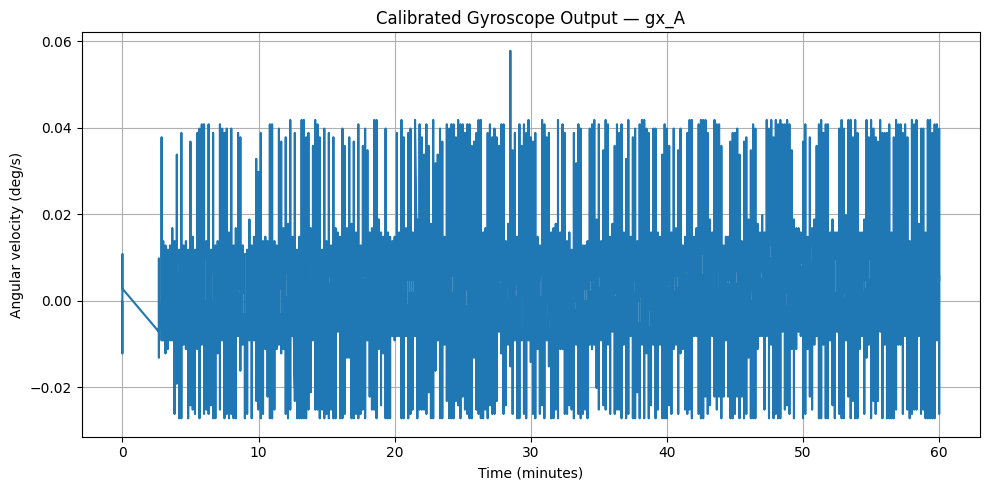

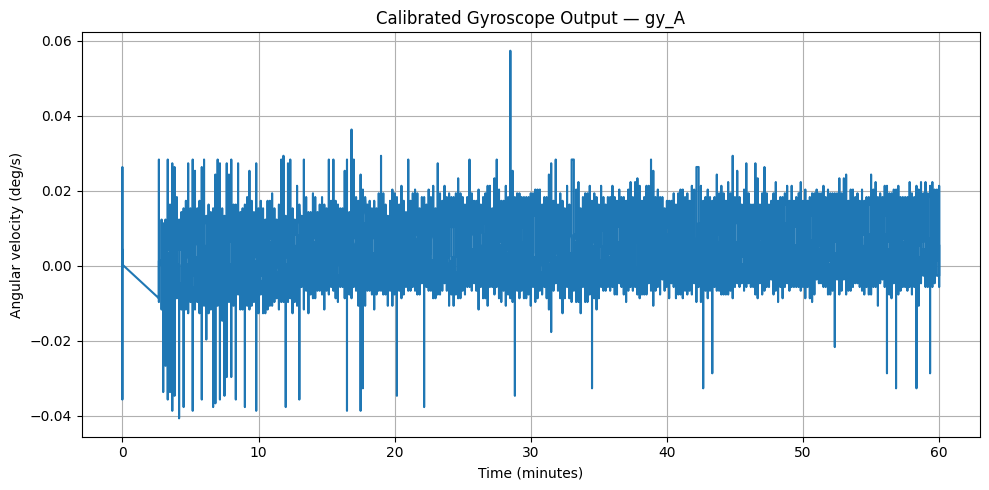

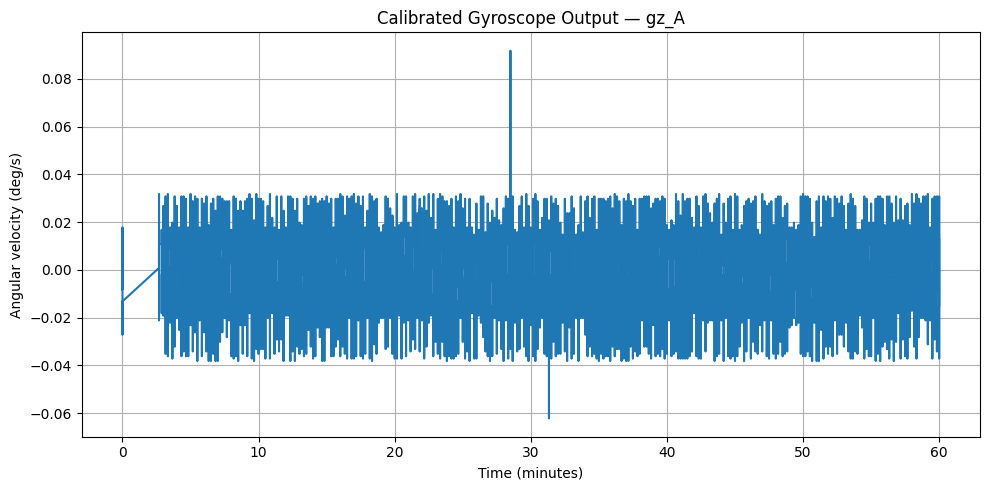

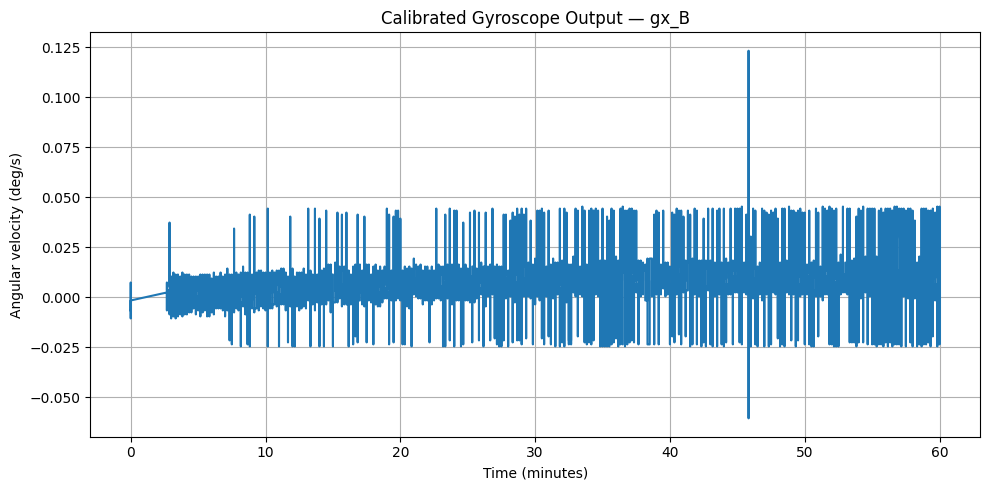

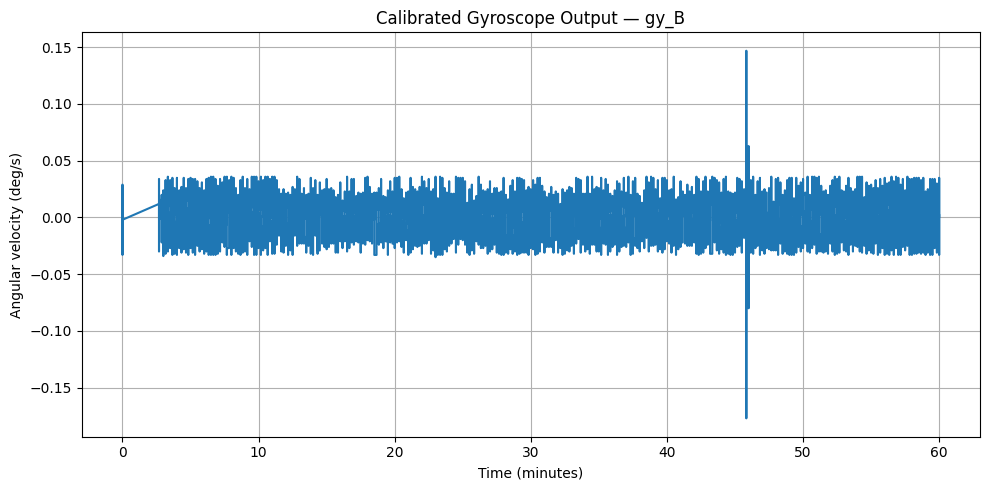

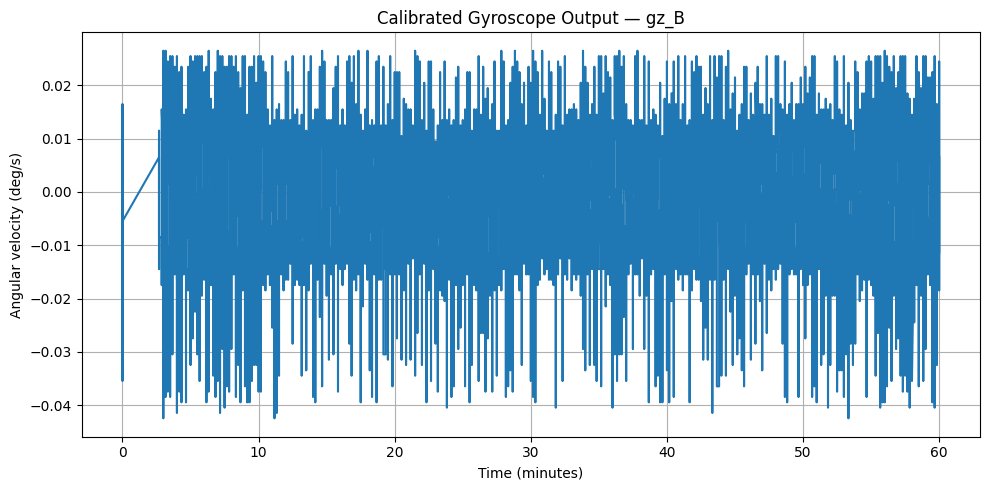

In [7]:
gyro_cols = ["gx_A", "gy_A", "gz_A", "gx_B", "gy_B", "gz_B"]

for col in gyro_cols:
    plt.figure(figsize=(10,5))
    plt.plot(df["t_sec"]/60, df[col])
    plt.xlabel("Time (minutes)")
    plt.ylabel("Angular velocity (deg/s)")
    plt.title(f"Calibrated Gyroscope Output — {col}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Median sample rate ~ 100.00 Hz


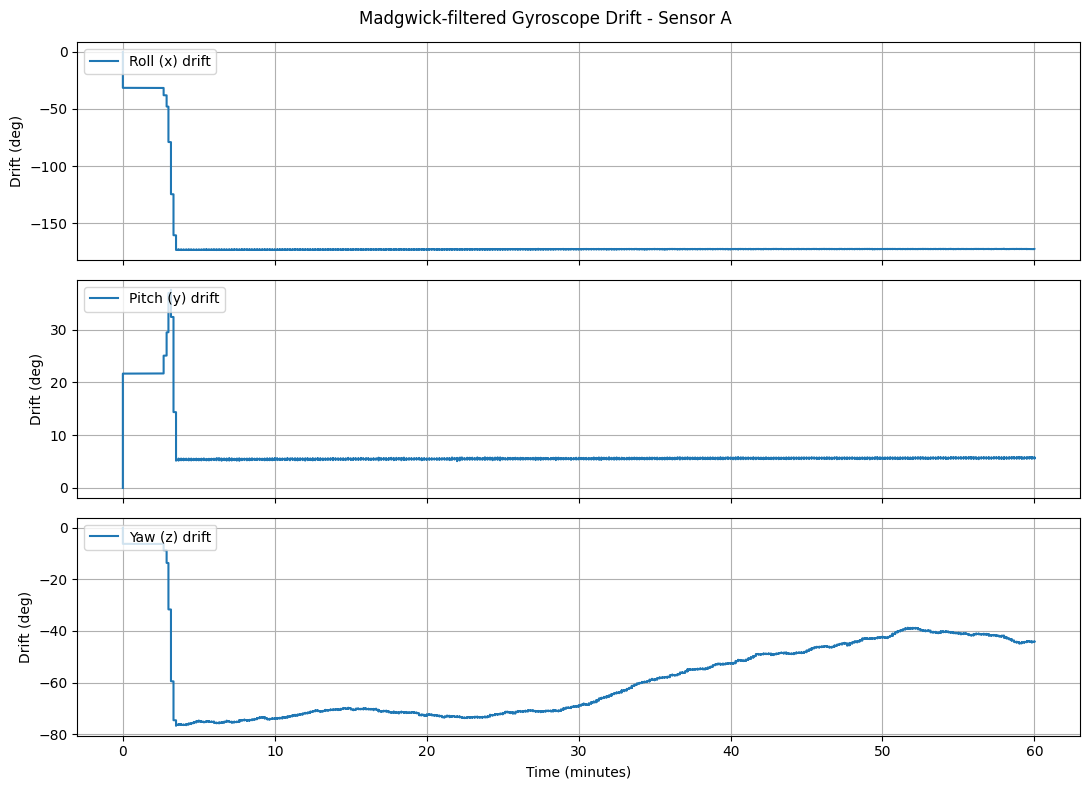

Sensor A Roll (x) drift rate: -6.6749 deg/hour
Sensor A Pitch (y) drift rate: -1.2448 deg/hour
Sensor A Yaw (z) drift rate: 41.6585 deg/hour


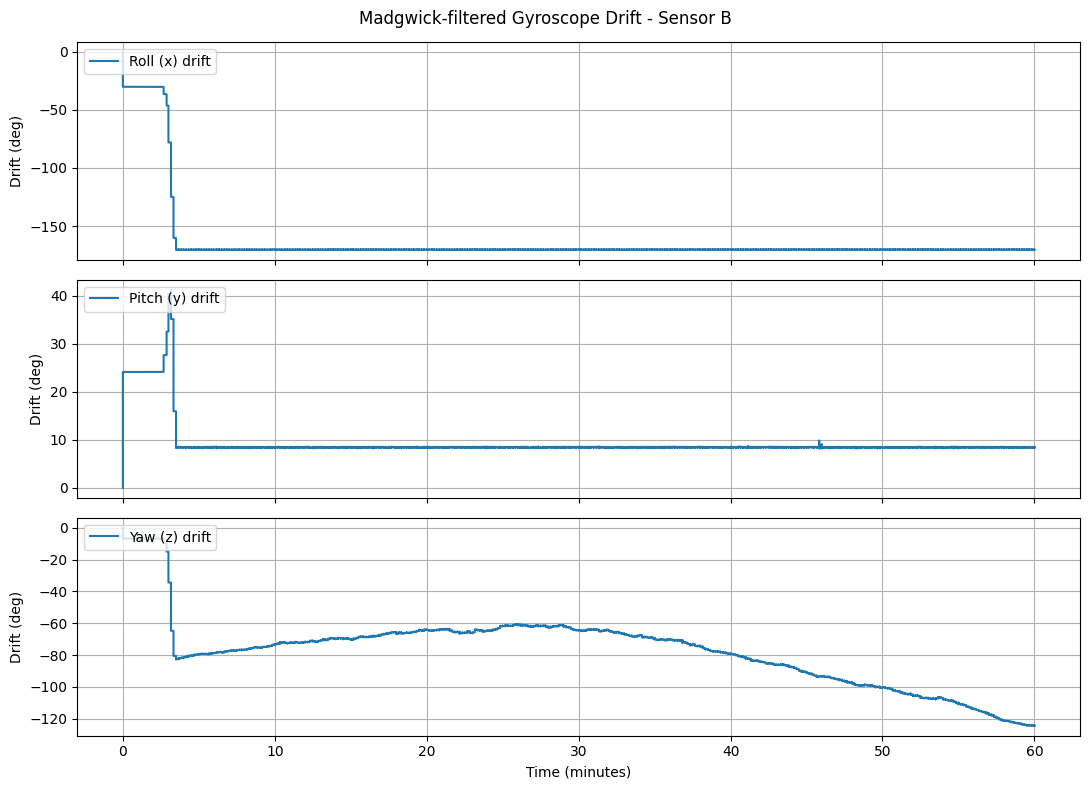

Sensor B Roll (x) drift rate: -7.1938 deg/hour
Sensor B Pitch (y) drift rate: -1.4999 deg/hour
Sensor B Yaw (z) drift rate: -50.3987 deg/hour


In [26]:
import sys
from pathlib import Path

try:
    from IPython import get_ipython
except ImportError:
    get_ipython = lambda: None

ip = get_ipython()
if ip is not None:
    try:
        ip.run_line_magic("load_ext", "autoreload")
        ip.run_line_magic("autoreload", "2")
    except Exception as exc:
        print(f"Could not enable autoreload: {exc}")

project_root = Path.cwd()
if not (project_root / 'elbow_rehab').exists():
    for parent in project_root.parents:
        if (parent / 'elbow_rehab').exists():
            project_root = parent
            break
if not (project_root / 'elbow_rehab').exists():
    raise RuntimeError("Cannot locate project root containing the 'elbow_rehab' package.")
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from elbow_rehab.service.angle_calculation.filters.madgwick import MadgwickFilter

imu_config = {
    'A': {'acc': ['ax_A', 'ay_A', 'az_A'], 'gyro': ['gx_A', 'gy_A', 'gz_A']},
    'B': {'acc': ['ax_B', 'ay_B', 'az_B'], 'gyro': ['gx_B', 'gy_B', 'gz_B']},
}

times = df['t_sec'].to_numpy()
dts = np.diff(times)
valid_dts = dts[dts > 0]
if valid_dts.size == 0:
    raise ValueError('Cannot estimate sample rate because all time deltas are non-positive.')
# sample_rate_hz = 1.0 / np.median(valid_dts)
sample_rate_hz = 100
print(f"Median sample rate ~ {sample_rate_hz:.2f} Hz")

labels = ['Roll (x)', 'Pitch (y)', 'Yaw (z)']
madgwick_drift = {}

for sensor, cols in imu_config.items():
    filt = MadgwickFilter(frequency=sample_rate_hz)
    acc = df[cols['acc']].to_numpy()
    gyro = df[cols['gyro']].to_numpy()

    angles = np.zeros((len(df), 3))
    for idx in range(len(df)):
        filt.update(acc[idx], gyro[idx])
        angles[idx] = filt.euler_angles(degrees=True)

    drift = angles - angles[0]
    madgwick_drift[sensor] = drift

    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for axis_idx, label in enumerate(labels):
        axes[axis_idx].plot(times / 60, drift[:, axis_idx], label=f"{label} drift")
        axes[axis_idx].set_ylabel('Drift (deg)')
        axes[axis_idx].grid(True)
        axes[axis_idx].legend(loc='upper left')

    axes[-1].set_xlabel('Time (minutes)')
    fig.suptitle(f"Madgwick-filtered Gyroscope Drift - Sensor {sensor}")
    fig.tight_layout()
    plt.show()

    for axis_idx, label in enumerate(labels):
        slope, intercept, *_ = stats.linregress(times, drift[:, axis_idx])
        print(f"Sensor {sensor} {label} drift rate: {slope * 3600:.4f} deg/hour")


In [11]:
print("Negative time steps:", (np.diff(df["t_sec"]) < 0).sum())


Negative time steps: 0
